# Barcelona vs PSG – Rivalry Analysis & Match Prediction
**Tonight:** UEFA Champions League league phase, MD3 – PSG vs Barcelona, **Parc des Princes** (PSG at home).

Plan: (1) head-to-head history, (2) stats we have, (3) current form from the league data, (4) probability model.

In [1]:
import pandas as pd, numpy as np, math, matplotlib.pyplot as plt
plt.style.use("seaborn-v0_8-whitegrid")
P="/mnt/user-data/uploads/"; B,PS="#1f4e9c","#e8741e"
m=pd.read_csv(P+"barcelona_vs_psg_matches.csv",parse_dates=["date"])
st=pd.read_csv(P+"barcelona_vs_psg_match_stats.csv")
# result from Barcelona's point of view
bg=np.where(m.home_team=="Barcelona",m.home_goals,m.away_goals); pg=np.where(m.home_team=="Barcelona",m.away_goals,m.home_goals)
m["BarcaG"],m["PsgG"]=bg,pg
m["Winner"]=np.select([bg>pg,bg<pg],["Barcelona","PSG"],"Draw")
t=m.Winner.value_counts().reindex(["Barcelona","Draw","PSG"])
print(f"{len(m)} matches | Barça {t['Barcelona']}W  Draw {t['Draw']}  PSG {t['PSG']}W | goals: Barça {bg.sum()} - {pg.sum()} PSG")
m.groupby("Winner").size().to_frame("Matches").T

16 matches | Barça 6W  Draw 4  PSG 6W | goals: Barça 29 - 29 PSG


Winner,Barcelona,Draw,PSG
Matches,6,4,6


## 1. Head-to-head history

Since 2015 goals/game: {'BarcaG': 2.0, 'PsgG': 2.11}
Last 3 meetings: 2023-24 Paris Saint-Germain 2 3           Barcelona
2023-24           Barcelona 1 4 Paris Saint-Germain
2025-26           Barcelona 1 2 Paris Saint-Germain


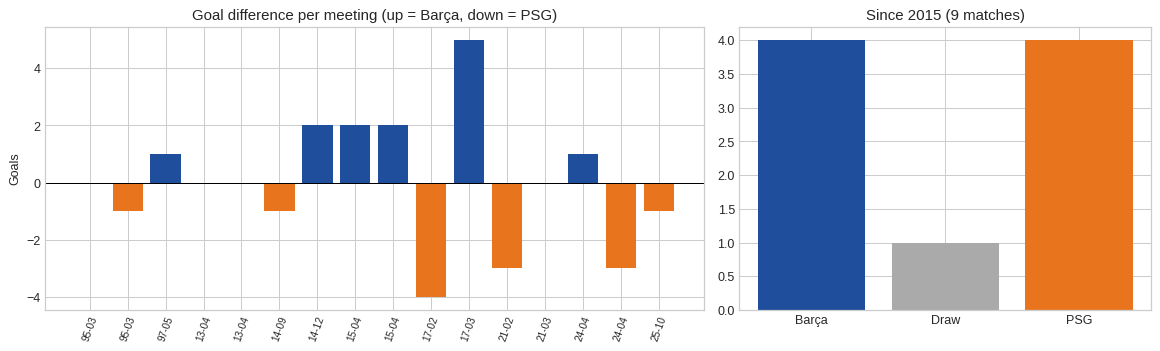

In [2]:
fig,ax=plt.subplots(1,2,figsize=(13,4),gridspec_kw={"width_ratios":[1.6,1]})
d=m.BarcaG-m.PsgG
ax[0].bar(range(len(m)),d,color=[B if x>0 else PS if x<0 else "#aaa" for x in d])
ax[0].set_xticks(range(len(m))); ax[0].set_xticklabels(m.date.dt.strftime("%y-%m"),rotation=70,fontsize=8)
ax[0].axhline(0,color="k",lw=.8); ax[0].set(title="Goal difference per meeting (up = Barça, down = PSG)",ylabel="Goals")
# last 6 meetings only (2015 onward is the modern era)
r=m[m.date>="2015-01-01"].Winner.value_counts().reindex(["Barcelona","Draw","PSG"]).fillna(0)
ax[1].bar(["Barça","Draw","PSG"],r.values,color=[B,"#aaa",PS]); ax[1].set(title="Since 2015 (%d matches)"%r.sum())
plt.tight_layout(); plt.show()
print("Since 2015 goals/game:",round((m[m.date>='2015-01-01'][['BarcaG','PsgG']].sum()/r.sum()),2).to_dict())
print("Last 3 meetings:",m.tail(3)[["season","home_team","home_goals","away_goals","away_team"]].to_string(index=False,header=False))

## 2. Match stats (sparse – many cells are missing in the file)

matches with data (shots, SoT, corners, xG): [9, 8, 9, 3]


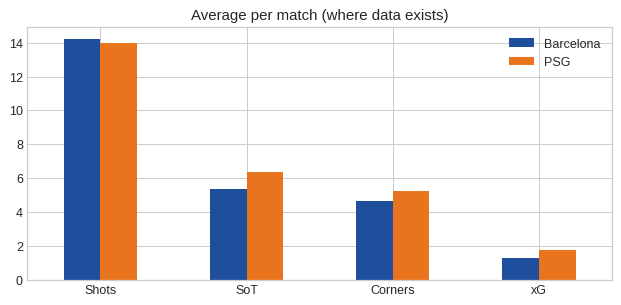

,Barcelona,PSG
Shots,14.22,14.00
SoT,5.38,6.38
Corners,4.67,5.22
xG,1.27,1.77


In [3]:
s=st.merge(m[["match_id","home_team","away_team"]],on="match_id")
bs=lambda c:np.where(s.home_team=="Barcelona",s["home_"+c],s["away_"+c]); ps=lambda c:np.where(s.home_team=="Barcelona",s["away_"+c],s["home_"+c])
cols=["shots","shots_on_target","corners","xg"]
cmp=pd.DataFrame({"Barcelona":[np.nanmean(bs(c)) for c in cols],"PSG":[np.nanmean(ps(c)) for c in cols]},index=["Shots","SoT","Corners","xG"])
n=[int(pd.Series(bs(c)).notna().sum()) for c in cols]; print("matches with data (shots, SoT, corners, xG):",n)
cmp.plot.bar(color=[B,PS],rot=0,figsize=(7,3.5),title="Average per match (where data exists)"); plt.tight_layout(); plt.show()
cmp.round(2)

## 3. Current form (league data from earlier)
Same `prep` logic as the form notebook: per-game goals for/against for 2025/26 and 2026/27.

In [4]:
def prep(path,team):
    d=pd.read_csv(P+path,encoding="utf-8-sig"); d=d[(d.HomeTeam==team)|(d.AwayTeam==team)]; h=d.HomeTeam==team
    return pd.DataFrame({"GF":d.FTHG.where(h,d.FTAG),"GA":d.FTAG.where(h,d.FTHG)})
F={"Barcelona":("laliga_25_26.csv","laliga_26_27.csv"),"PSG":("F1__1_.csv","F1.csv")}; T={"Barcelona":"Barcelona","PSG":"Paris SG"}
form={}
for k,(a,b) in F.items():
    x,y=prep(a,T[k]),prep(b,T[k])
    w25,w26=len(x),len(y)*1.5            # recent games count 1.5x
    att=(x.GF.mean()*w25+y.GF.mean()*w26)/(w25+w26); de=(x.GA.mean()*w25+y.GA.mean()*w26)/(w25+w26)
    k0=10; PRIOR=1.4                      # shrink toward an average team (10 pseudo-games)
    n=w25+w26; form[k]={"att":(att*n+PRIOR*k0)/(n+k0),"def":(de*n+PRIOR*k0)/(n+k0),
        "26/27 GF":y.GF.mean(),"26/27 GA":y.GA.mean(),"25/26 GF":x.GF.mean(),"25/26 GA":x.GA.mean(),
        "26/27 pts/g":((y.GF>y.GA)*3+(y.GF==y.GA)).mean(),"25/26 pts/g":((x.GF>x.GA)*3+(x.GF==x.GA)).mean()}
f=pd.DataFrame(form).round(2); f

,Barcelona,PSG
att,2.67,1.97
def,1.01,1.04
26/27 GF,4.25,1.83
26/27 GA,0.88,1.33
25/26 GF,2.50,2.18
25/26 GA,0.95,0.85
26/27 pts/g,3.00,1.83
25/26 pts/g,2.47,2.24


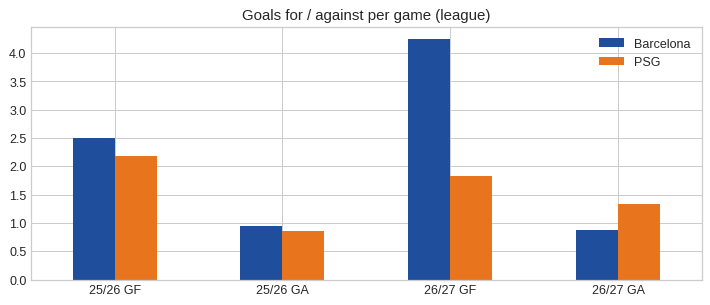

In [5]:
f.loc[["25/26 GF","25/26 GA","26/27 GF","26/27 GA"]].plot.bar(color=[B,PS],rot=0,figsize=(8,3.5),title="Goals for / against per game (league)")
plt.tight_layout(); plt.show()

## 4. Probability model
**Model A – form (Poisson):** expected goals = average of one side's attack and the other's defence, with a home boost for PSG (+10%) and a small penalty for Barça (−8%). Scoreline probabilities come from two independent Poisson distributions.

**Model B – head-to-head:** all 16 meetings, recent ones weighted more (half-life 6 years).

**Market check:** average bookmaker odds (≈2.40 PSG / 4.20 draw / 2.45 Barça) converted to probabilities with the margin removed.

**Final = 50% A + 20% B + 30% market.** These weights are judgement calls, not fitted.

In [6]:
# Model A
lp=(form["PSG"]["att"]+form["Barcelona"]["def"])/2*1.10
lb=(form["Barcelona"]["att"]+form["PSG"]["def"])/2*0.92
pois=lambda l,k:math.exp(-l)*l**k/math.factorial(k)
M=np.array([[pois(lp,i)*pois(lb,j) for j in range(7)] for i in range(7)])   # rows=PSG goals, cols=Barça goals
A=np.array([np.tril(M,-1).sum(),np.trace(M),np.triu(M,1).sum()]); A/=A.sum()   # PSG, Draw, Barça
# Model B
age=(pd.Timestamp("2026-10-20")-m.date).dt.days/365.25; w=0.5**(age/6)
B_=np.array([w[m.Winner=="PSG"].sum()+.5,w[m.Winner=="Draw"].sum()+.5,w[m.Winner=="Barcelona"].sum()+.5]); B_/=B_.sum()
# Market
o=np.array([1/2.40,1/4.20,1/2.45]); Mk=o/o.sum()
final=.5*A+.2*B_+.3*Mk
res=pd.DataFrame([A,B_,Mk,final],index=["A: form model","B: head-to-head","Market","FINAL"],columns=["PSG win","Draw","Barça win"])*100
print(f"Expected goals  PSG {lp:.2f} - {lb:.2f} Barça")
res.round(1)

Expected goals  PSG 1.64 - 1.70 Barça


,PSG win,Draw,Barça win
A: form model,37.2,22.9,39.9
B: head-to-head,45.7,20.6,33.6
Market,39.2,22.4,38.4
FINAL,39.5,22.3,38.2


Most likely scores (PSG-Barça): 1-1 (10%), 1-2 (8%), 2-1 (8%)
Over 2.5 goals: 65%  |  Both teams score: 66%


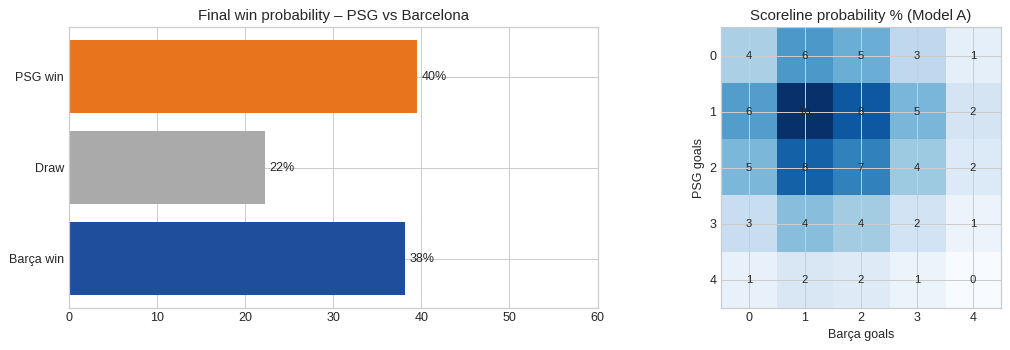

In [7]:
fig,ax=plt.subplots(1,2,figsize=(13,4),gridspec_kw={"width_ratios":[1,1.1]})
fp=final*100; ax[0].barh(["Barça win","Draw","PSG win"],fp[::-1],color=[B,"#aaa",PS])
for i,v in enumerate(fp[::-1]): ax[0].text(v+.5,i,f"{v:.0f}%",va="center")
ax[0].set(title="Final win probability – PSG vs Barcelona",xlim=(0,60))
im=ax[1].imshow(M[:5,:5]*100,cmap="Blues"); ax[1].set(title="Scoreline probability % (Model A)",xlabel="Barça goals",ylabel="PSG goals")
for i in range(5):
    for j in range(5): ax[1].text(j,i,f"{M[i,j]*100:.0f}",ha="center",va="center",fontsize=9)
plt.tight_layout(); plt.show()
top=sorted(((M[i,j],i,j) for i in range(7) for j in range(7)),reverse=True)[:3]
print("Most likely scores (PSG-Barça):",", ".join(f"{i}-{j} ({p*100:.0f}%)" for p,i,j in top))
print(f"Over 2.5 goals: {M[np.add.outer(range(7),range(7))>2].sum()*100:.0f}%  |  Both teams score: {M[1:,1:].sum()*100:.0f}%")

## 5. Verdict & caveats
- The model sees this as a **near coin-flip with a very slight PSG edge** (home advantage plus the defending champions' record), and a draw is a realistic ~1 in 4 outcome.
- Barça's 2026/27 numbers (4.25 goals/game) are inflated by league opposition; the shrinkage step deliberately pulls them back.
- Not modelled: injuries (e.g. De Jong is listed as missing), line-ups, rotation, Champions League form, referee, motivation.
- The head-to-head stats file has many empty cells, so Section 2 is only indicative.
- Educational analysis, not betting advice.